# Назначение самолёта по фотографии: сравнение двух локальных VLM

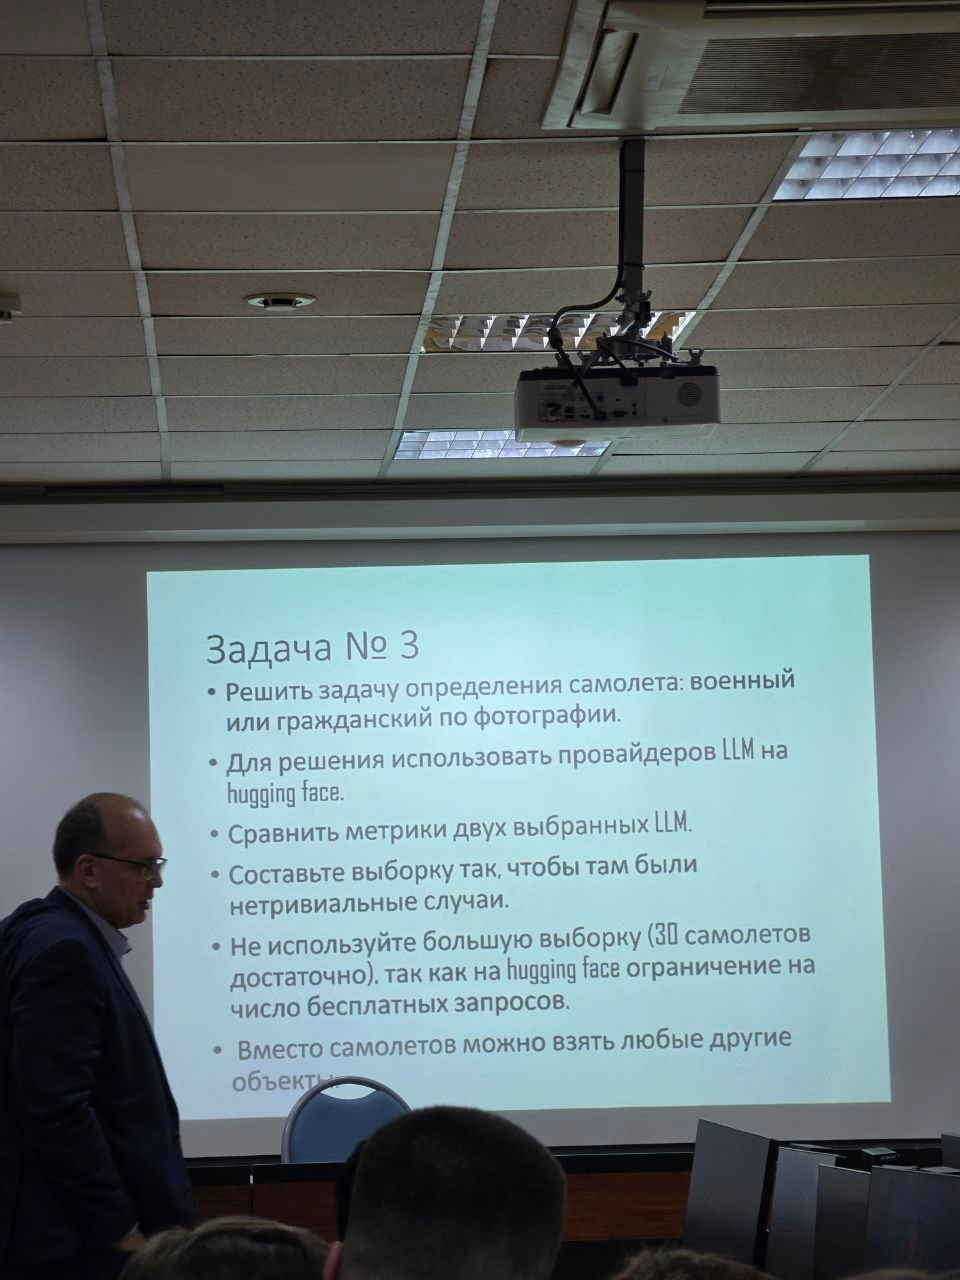

Задача № 3- Решить задачу определения самолета: военный или гражданский по фотографии.
- Для решения использовать провайдеров LLM на hugging face.
- Сравнить метрики двух выбранных LLM.
- Составьте выборку так, чтобы там были нетривиальные случаи.
- Не используйте большую выборку (30 самолетов достаточно), так как на hugging face ограничение на число бесплатных запросов.
- Вместо самолетов можно взять любые другие объекты.

Исследуется классификация назначения самолётов на выборке из 30 изображений test split FGVC-Aircraft 2013b. Сопоставляются Qwen2.5-VL-3B-Instruct (`qwen2.5vl:3b`) и Gemma 3 4B IT (`gemma3:4b`). Каждый полный запуск выполняет новый запрос к каждой модели для каждого изображения. Бинарные метки назначены по варианту. Гражданская часть содержит пассажирские и региональные типы, поэтому результаты не обобщаются на малые гражданские самолёты и сложные случаи.

Источник: FGVC-Aircraft <https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/>; Maji et al., *Fine-Grained Visual Classification of Aircraft* (2013). Исследование проводится локально; API моделей передаются только исходные байты JPEG.

## Подготовка выборки

Архив FGVC-Aircraft проверяется по MD5 `d4acdd33327262359767eeaa97a4f732`; на странице Oxford опубликовано другое значение `32eca553f897e747706144f3bb444df0`. Манифест задаёт неизменный состав выборки. При отсутствии архива он загружается с официальной страницы; при отсутствии выбранных JPEG они извлекаются из архива, а существующие файлы только проверяются по SHA-256.

In [1]:
from pathlib import Path
import csv, hashlib, tarfile, urllib.request, json, time, base64, os
from collections import Counter
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / 'data'
IMAGES = DATA / 'images'
DATA.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)
ARCHIVE = DATA / 'fgvc-aircraft-2013b.tar.gz'
ARCHIVE_URL = 'https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/data/fgvc-aircraft-2013b.tar.gz'
ARCHIVE_MD5 = 'd4acdd33327262359767eeaa97a4f732'
OXFORD_MD5 = '32eca553f897e747706144f3bb444df0'

# Состав выборки закреплён в манифесте; проверка архива и SHA-256 сохраняет неизменность уже существующих снимков
def prepare_dataset():
    manifest_path = DATA / 'manifest.csv'
    if not ARCHIVE.exists():
        temporary = ARCHIVE.with_suffix('.download')
        try:
            urllib.request.urlretrieve(ARCHIVE_URL, temporary)
            temporary.replace(ARCHIVE)
        finally:
            temporary.unlink(missing_ok=True)
    digest = hashlib.md5(ARCHIVE.read_bytes()).hexdigest()
    assert digest == ARCHIVE_MD5, f'Archive MD5 mismatch: {digest}'
    print(f'Archive verified: {digest}; Oxford published value differs: {OXFORD_MD5}')
    sample = {'0704268': 'civilian', '1881962': 'civilian', '1818227': 'civilian', '1237861': 'civilian', '0127496': 'civilian', '1700645': 'civilian', '1396941': 'civilian', '0065291': 'civilian', '0422938': 'civilian', '1788036': 'civilian', '1601262': 'civilian', '1586117': 'civilian', '1647701': 'civilian', '1222169': 'civilian', '0066278': 'civilian', '1317747': 'military', '2186726': 'military', '1997801': 'military', '1375880': 'military', '1362024': 'military', '0747565': 'military', '0141433': 'military', '1120498': 'military', '1764706': 'military', '2118873': 'military', '1966899': 'military', '1898052': 'military', '1244763': 'military', '1570911': 'military', '2163696': 'military'}
    if not manifest_path.exists():
        with tarfile.open(ARCHIVE, 'r:gz') as source:
            members = {Path(member.name).name: member for member in source.getmembers() if member.isfile()}
            variants = source.extractfile(members['images_variant_test.txt']).read().decode().splitlines()
            boxes = source.extractfile(members['images_box.txt']).read().decode().splitlines()
            variants_by_id = {line.split(' ', 1)[0]: line.split(' ', 1)[1] for line in variants}
            boxes_by_id = {line.split()[0]: line.split()[1:] for line in boxes}
            rows = []
            for image_id, label in sample.items():
                box = list(map(int, boxes_by_id[image_id]))
                image_member = members[f'{image_id}.jpg']
                image_bytes = source.extractfile(image_member).read()
                rows.append({'image_id': image_id, 'variant': variants_by_id[image_id], 'split': 'test', 'label': label, 'selection_reason': 'Approved fixed sample', 'difficulty': 'not independently assessed', 'source': 'Oxford FGVC-Aircraft 2013b', 'source_md5': ARCHIVE_MD5, 'image_sha256': hashlib.sha256(image_bytes).hexdigest(), 'bbox_xyxy': ','.join(map(str, box))})
        generated_manifest = DATA / 'manifest.csv.tmp'
        with generated_manifest.open('w', newline='', encoding='utf-8') as handle:
            writer = csv.DictWriter(handle, fieldnames=rows[0].keys())
            writer.writeheader()
            writer.writerows(rows)
        generated_manifest.replace(manifest_path)
    rows = list(csv.DictReader(manifest_path.open(encoding='utf-8')))
    assert len(rows) == 30 and {row['image_id'] for row in rows} == set(sample)
    assert Counter(row['label'] for row in rows) == {'civilian': 15, 'military': 15}
    with tarfile.open(ARCHIVE, 'r:gz') as archive:
        names = {Path(member.name).name: member for member in archive.getmembers() if member.isfile()}
        variants = {line.split(' ', 1)[0]: line.split(' ', 1)[1] for line in archive.extractfile(names['images_variant_test.txt']).read().decode().splitlines()}
        boxes = {line.split()[0]: ','.join(line.split()[1:]) for line in archive.extractfile(names['images_box.txt']).read().decode().splitlines()}
        for row in rows:
            assert row['label'] == sample[row['image_id']] and row['variant'] == variants[row['image_id']] and row['split'] == 'test'
            assert row['source_md5'] == ARCHIVE_MD5 and row['bbox_xyxy'] == boxes[row['image_id']], f'Manifest does not match pinned archive annotations: {row["image_id"]}'
            image_path = IMAGES / f"{row['image_id']}.jpg"
            member = names.get(f"{row['image_id']}.jpg")
            if member is None:
                raise FileNotFoundError(f"Image not found in official archive: {row['image_id']}")
            original_bytes = archive.extractfile(member).read()
            assert hashlib.sha256(original_bytes).hexdigest() == row['image_sha256'], f"Manifest image hash differs from archive: {row['image_id']}"
            if not image_path.exists():
                image_path.write_bytes(original_bytes)
            actual = hashlib.sha256(image_path.read_bytes()).hexdigest()
            assert actual == row['image_sha256'], f"JPEG SHA-256 mismatch: {row['image_id']}"
    print(f'Validated {len(rows)} original test images; labels: {dict(Counter(row["label"] for row in rows))}')
    return rows

manifest = prepare_dataset()

Archive verified: d4acdd33327262359767eeaa97a4f732; Oxford published value differs: 32eca553f897e747706144f3bb444df0


Validated 30 original test images; labels: {'civilian': 15, 'military': 15}


## Контактный лист

Рамки FGVC применяются только к отображению. Запросы к моделям используют полный исходный JPEG, который сверяется с хешем из манифеста.

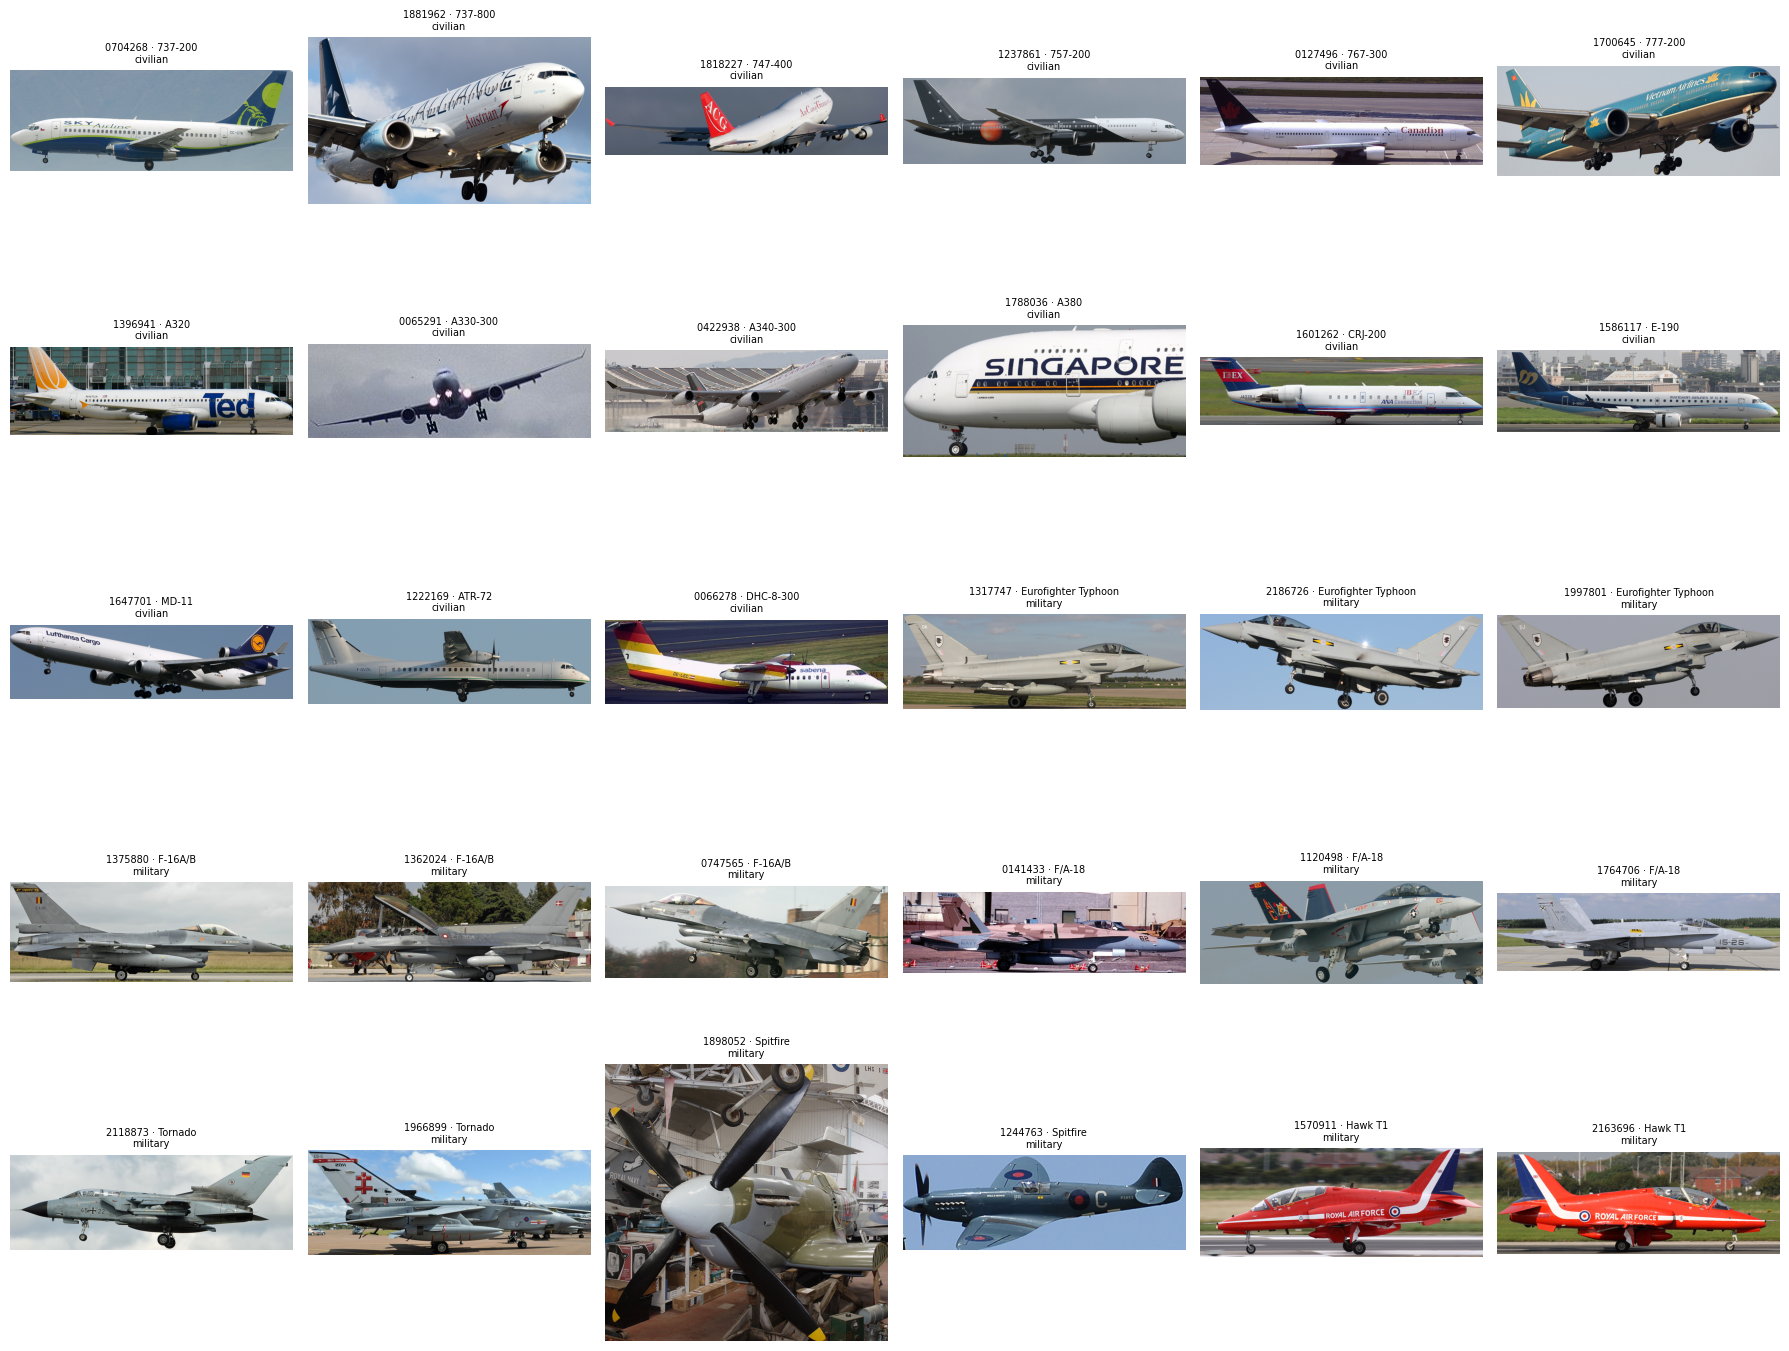

In [2]:
fig, axes = plt.subplots(5, 6, figsize=(18, 14))
for ax, row in zip(axes.flat, manifest):
    with Image.open(IMAGES / f"{row['image_id']}.jpg") as image:
        x0, y0, x1, y1 = map(int, row['bbox_xyxy'].split(','))
        ax.imshow(image.crop((x0, y0, x1, y1)))
    ax.set_title(f"{row['image_id']} · {row['variant']}\n{row['label']}", fontsize=7)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Подключение Ollama и проверочный запрос

Проверяется версия сервера, а отсутствующие точные теги загружаются через `/api/pull`. Digest сохраняется в записях результатов. Проверочный запрос подтверждает, что каждая модель принимает изображение и возвращает одну из заданных меток. Таймаут 600 секунд относится к одному HTTP-запросу.

In [3]:
OLLAMA_URL = 'http://practice3-ollama:11434'
MODELS = ('qwen2.5vl:3b', 'gemma3:4b')
PROMPT = 'Определите основное назначение самолёта. Верните JSON-объект строго вида {"label": "civilian"} или {"label": "military"}.'
OPTIONS = {'temperature': 0, 'num_ctx': 4096, 'num_predict': 32}
REQUEST_TIMEOUT = 600

# Метка принимается из JSON-поля label или как точная строка; иной формат остаётся невалидным
def parse_label(raw):
    try:
        value = json.loads(raw)
    except (json.JSONDecodeError, TypeError):
        value = None
    if isinstance(value, dict) and value.get('label') in ('civilian', 'military'):
        return value['label']
    return raw.strip() if isinstance(raw, str) and raw.strip() in ('civilian', 'military') else ''

# Задержка охватывает HTTP-запрос целиком, а сетевые сбои и неверный JSON возвращаются как диагностика
def call_model(model, payload):
    body = {'model': model, 'messages': [{'role': 'user', 'content': PROMPT, 'images': [base64.b64encode(payload).decode('ascii')]}], 'stream': False, 'format': 'json', 'options': OPTIONS}
    started = time.perf_counter()
    try:
        response = requests.post(f'{OLLAMA_URL}/api/chat', json=body, timeout=REQUEST_TIMEOUT)
        response.raise_for_status()
        try:
            return response.json(), time.perf_counter() - started, ''
        except (requests.exceptions.JSONDecodeError, ValueError) as exc:
            return {}, time.perf_counter() - started, f'Malformed JSON: {exc}'
    except requests.RequestException as exc:
        return {}, time.perf_counter() - started, f'{type(exc).__name__}: {exc}'

version_response = requests.get(f'{OLLAMA_URL}/api/version', timeout=30)
version_response.raise_for_status()
ollama_version = version_response.json()['version']
print(f'Ollama version: {ollama_version}')
# Теги загружаются перед опытом, а их digest связывает ответы с конкретными версиями моделей
for model in MODELS:
    pull_response = requests.post(f'{OLLAMA_URL}/api/pull', json={'name': model, 'stream': False}, timeout=1800)
    pull_response.raise_for_status()
tags_response = requests.get(f'{OLLAMA_URL}/api/tags', timeout=30)
tags_response.raise_for_status()
tag_rows = {item['name']: item for item in tags_response.json().get('models', [])}
digests = {model: tag_rows[model]['digest'] for model in MODELS if model in tag_rows}
assert len(digests) == 2, f'Model tags missing after pull: {set(MODELS) - set(digests)}'
pilot_bytes = (IMAGES / f"{manifest[0]['image_id']}.jpg").read_bytes()
for model in MODELS:
    pilot, _, error = call_model(model, pilot_bytes)
    raw = pilot.get('message', {}).get('content', '')
    assert not error and parse_label(raw), f'Invalid pilot response from {model}: {error or raw}'
print('Visual pilot passed for both models.')

Ollama version: 0.30.7


Visual pilot passed for both models.


## Полный сбор ответов

Для каждого из 30 изображений выполняется отдельный свежий запрос каждой модели. Все строки, включая ошибки и невалидные ответы, остаются видимыми в текущем эксперименте. 

In [4]:
fields = ['model', 'model_digest', 'ollama_version', 'image_id', 'variant', 'ground_truth', 'status', 'predicted_label', 'raw_response', 'error', 'wall_seconds', 'server_seconds', 'prepared_sha256']
records = []
for model in MODELS:
    for row in manifest:
        image_bytes = (IMAGES / f"{row['image_id']}.jpg").read_bytes()
        image_hash = hashlib.sha256(image_bytes).hexdigest()
        assert image_hash == row['image_sha256'], f"JPEG changed during run: {row['image_id']}"
        try:
            answer, elapsed, error = call_model(model, image_bytes)
        except Exception as exc:
            answer, elapsed, error = {}, 0.0, f'{type(exc).__name__}: {exc}'
        raw = answer.get('message', {}).get('content', '')
        predicted = parse_label(raw) if not error else ''
        # Успех требует валидной метки; таймаут, прочая ошибка и пустой разбор различаются по статусу
        status = 'timeout' if 'Timeout' in error else ('error' if error else ('ok' if predicted else 'invalid'))
        server_ns = answer.get('total_duration')
        records.append({'model': model, 'model_digest': digests[model], 'ollama_version': ollama_version, 'image_id': row['image_id'], 'variant': row['variant'], 'ground_truth': row['label'], 'status': status, 'predicted_label': predicted, 'raw_response': raw, 'error': error, 'wall_seconds': elapsed, 'server_seconds': server_ns / 1e9 if server_ns is not None else '', 'prepared_sha256': image_hash})
        print(f"{model} {row['image_id']}: {status}, {elapsed:.2f}s")

expected = {(model, row['image_id']) for model in MODELS for row in manifest}
actual = {(record['model'], record['image_id']) for record in records}
failed = [record for record in records if record['status'] != 'ok']
# Неполный или неуспешный прогон сохраняется отдельно и не затрагивает последний полный CSV
if len(records) != 60 or actual != expected or failed:
    partial_results = DATA / 'results-partial.csv'
    with partial_results.open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    details = ', '.join(f"{record['model']}/{record['image_id']}={record['status']}" for record in failed) or 'missing/duplicate pairs'
    raise RuntimeError(f'Collection failed: {len(records)}/60 responses; {len(failed)} failed pairs; {details}. Partial results: {partial_results}')
# Сначала записывается временный файл; заменяется только готовый полный результат
temporary_results = DATA / 'results.csv.tmp'
with temporary_results.open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=fields)
    writer.writeheader()
    writer.writerows(records)
temporary_results.replace(DATA / 'results.csv')
df = pd.DataFrame(records)
print(f'Completed fresh collection: {len(df)} records; {df["status"].value_counts().to_dict()}')

qwen2.5vl:3b 0704268: ok, 31.48s


qwen2.5vl:3b 1881962: ok, 61.87s


qwen2.5vl:3b 1818227: ok, 27.36s


qwen2.5vl:3b 1237861: ok, 27.69s


qwen2.5vl:3b 0127496: ok, 27.27s


...

gemma3:4b 1966899: ok, 22.91s


gemma3:4b 1898052: ok, 24.39s


gemma3:4b 1244763: ok, 23.04s


gemma3:4b 1570911: ok, 22.76s


gemma3:4b 2163696: ok, 23.91s
Completed fresh collection: 60 records; {'ok': 60}


## Метрики, матрицы ошибок и задержки

Показатели рассчитываются из массива текущего запуска. Ошибочные и невалидные ответы остаются в знаменателе accuracy и отображаются отдельным столбцом матрицы. Времена сравниваются с ориентиром 120 секунд без предположения о гарантированном соблюдении порога.

,model,accuracy,invalid_or_timeout,within_120s,requests,median_wall_s,max_wall_s,civilian_precision,civilian_recall,civilian_f1,military_precision,military_recall,military_f1
0,qwen2.5vl:3b,1.0,0,30,30,27.348796,61.872737,1.0,1.0,1.0,1.0,1.0,1.0
1,gemma3:4b,1.0,0,30,30,23.006861,30.328044,1.0,1.0,1.0,1.0,1.0,1.0


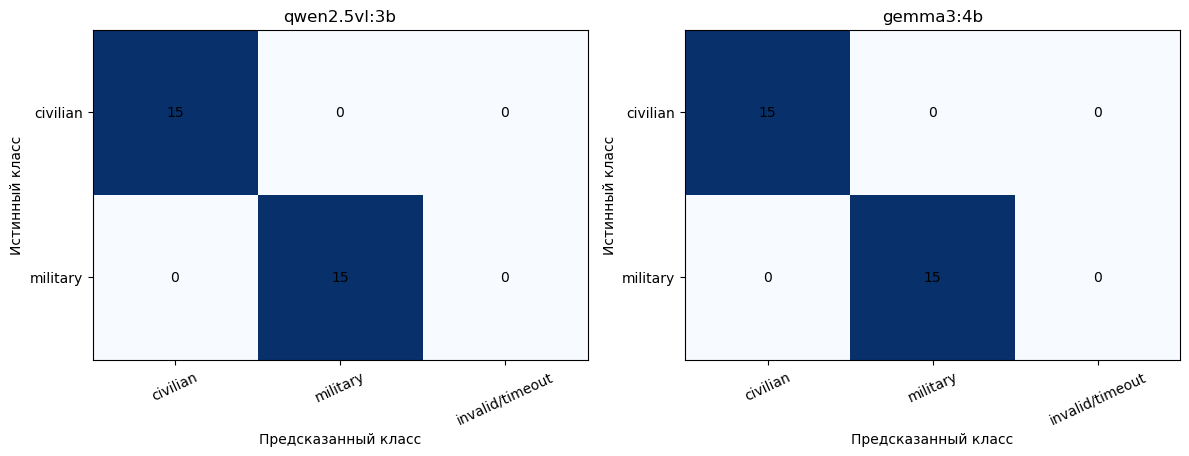

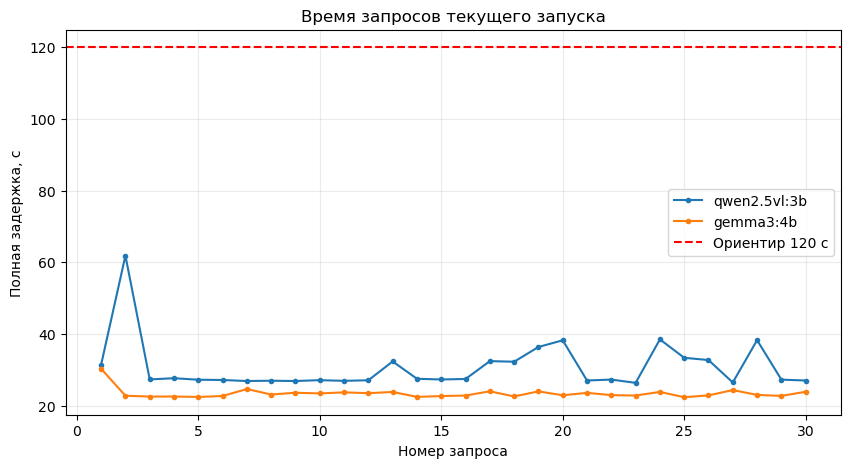

qwen2.5vl:3b: accuracy 100.0%; within 120s 30/30; median 27.35s; max 61.87s; invalid/timeout 0
gemma3:4b: accuracy 100.0%; within 120s 30/30; median 23.01s; max 30.33s; invalid/timeout 0
Итог текущего сбора: все 60 запросов завершились валидными ответами.


In [5]:
from sklearn.metrics import precision_recall_fscore_support
labels = ['civilian', 'military']
summaries = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for index, model in enumerate(MODELS):
    group = df[df['model'] == model]
    truth = group['ground_truth'].tolist()
    # Ошибки и таймауты не исключаются из accuracy и попадают в отдельный столбец матрицы
    predictions = [value if status == 'ok' and value in labels else 'invalid/timeout' for value, status in zip(group['predicted_label'], group['status'])]
    safe_predictions = [value if value in labels else '__invalid__' for value in predictions]
    precision, recall, f1, _ = precision_recall_fscore_support(truth, safe_predictions, labels=labels, zero_division=0)
    wall = group['wall_seconds'].astype(float)
    summaries.append({'model': model, 'accuracy': sum(a == b for a, b in zip(truth, safe_predictions)) / len(truth), 'invalid_or_timeout': predictions.count('invalid/timeout'), 'within_120s': int((wall <= 120).sum()), 'requests': len(group), 'median_wall_s': wall.median(), 'max_wall_s': wall.max(), 'civilian_precision': precision[0], 'civilian_recall': recall[0], 'civilian_f1': f1[0], 'military_precision': precision[1], 'military_recall': recall[1], 'military_f1': f1[1]})
    matrix = [[sum(t == target and pred == column for t, pred in zip(truth, predictions)) for column in labels + ['invalid/timeout']] for target in labels]
    axes[index].imshow(matrix, cmap='Blues')
    axes[index].set(xticks=range(3), yticks=range(2), xticklabels=labels + ['invalid/timeout'], yticklabels=labels, xlabel='Предсказанный класс', ylabel='Истинный класс', title=model)
    for (i, j), value in __import__('numpy').ndenumerate(matrix):
        axes[index].text(j, i, str(value), ha='center', va='center')
    axes[index].tick_params(axis='x', labelrotation=25)
summary = pd.DataFrame(summaries)
display(summary)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(10, 5))
for model in MODELS:
    group = df[df['model'] == model]
    ax.plot(range(1, len(group) + 1), group['wall_seconds'], marker='.', label=model)
ax.axhline(120, color='red', linestyle='--', label='Ориентир 120 с')
ax.set(xlabel='Номер запроса', ylabel='Полная задержка, с', title='Время запросов текущего запуска')
ax.legend(); ax.grid(alpha=.25); plt.show()
for row in summaries:
    print(f"{row['model']}: accuracy {row['accuracy']:.1%}; within 120s {row['within_120s']}/{row['requests']}; median {row['median_wall_s']:.2f}s; max {row['max_wall_s']:.2f}s; invalid/timeout {row['invalid_or_timeout']}")
if df['status'].eq('ok').all() and len(df) == 60:
    print('Итог текущего сбора: все 60 запросов завершились валидными ответами.')
else:
    failed_pairs = df.loc[df['status'] != 'ok', ['model', 'image_id', 'status']]
    print(f'Итог текущего сбора: успешно {int(df["status"].eq("ok").sum())}/60; неуспешные пары: {failed_pairs.to_dict("records")}')

# Вывод
На выбранных 30 фотографиях обе модели верно определили назначение самолёта во всех случаях — 30 из 30. По качеству классификации различий в этом эксперименте не выявлено. При этом Gemma 3 4B работала быстрее: медианное время обработки составило 23,01 с против 27,35 с у Qwen2.5-VL-3B; максимальное — 30,33 с против 61,87 с. Все запросы уложились в предел 120 секунд на фотографию.

Выборка мала, а её гражданская часть состоит преимущественно из пассажирских и региональных самолётов. Поэтому результат 30/30 не доказывает одинаковую точность моделей на более сложных снимках и других типах авиации.